# Red Wine Quality

## Câu 9. Phân lớp Gaussian Naïve Bayes

### Yêu cầu

Xây dựng GaussianNB theo hướng dẫn; dự đoán và đánh giá trên tập kiểm thử.

### Dữ liệu và phương pháp

Thuộc tính quyết định: quality. Sử dụng toàn bộ dữ liệu được cung cấp. Chia huấn luyện 70%, kiểm thử 30%, random_state=42 theo đề. Tương quan cao được quy ước là |r| ≥ 0,8 giữa các thuộc tính đầu vào; giữ cột đứng trước trong thứ tự gốc. Chỉ số được trình bày theo từng lớp; precision/recall không xác định do mẫu số bằng 0 được quy ước bằng 0 và nêu rõ các lớp không được dự đoán.

In [1]:
print("Đặng Ngọc Hiếu - 6451071024")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "datasets").is_dir():
    if (ROOT / "6451071024_Lab2" / "datasets").is_dir():
        ROOT = ROOT / "6451071024_Lab2"
        break
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy thư mục datasets của LAB2.")
    ROOT = ROOT.parent
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", font="DejaVu Sans")


raw = pd.read_csv(ROOT / "datasets/wine/winequality-red.csv")
TARGET = "quality"
if TARGET not in raw or raw.empty or raw.isna().any().any():
    raise ValueError("Kiểm tra dữ liệu Wine: cần có quality và không có ô trống.")
data = raw.copy()


Đặng Ngọc Hiếu - 6451071024


In [2]:
print("Đặng Ngọc Hiếu - 6451071024")

# Tái hiện bước chọn thuộc tính của câu 3, không vẽ lại heatmap.
corr = data.drop(columns=TARGET).select_dtypes(include="number").corr(method="pearson")
CORRELATION_THRESHOLD = 0.8
# |r| >= 0,8 là quy ước đã nêu trong phương pháp, không phải ngưỡng đề ấn định.
drop_columns = []
for j, column in enumerate(corr.columns):
    for previous in corr.columns[:j]:
        value = corr.loc[previous, column]
        if previous not in drop_columns and pd.notna(value) and abs(value) >= CORRELATION_THRESHOLD:
            drop_columns.append(column)
            break
data = data.drop(columns=drop_columns)


Đặng Ngọc Hiếu - 6451071024


In [3]:
print("Đặng Ngọc Hiếu - 6451071024")

features = data.drop(columns=TARGET)
labels = data[TARGET]


Đặng Ngọc Hiếu - 6451071024


In [4]:
print("Đặng Ngọc Hiếu - 6451071024")

non_numeric = features.select_dtypes(exclude=["number", "bool"]).columns.tolist()
# uint8 lưu đúng 0/1 với một byte cho mỗi phần tử one-hot.
features_onehot = pd.get_dummies(features, columns=non_numeric, dtype="uint8")


Đặng Ngọc Hiếu - 6451071024


In [5]:
print("Đặng Ngọc Hiếu - 6451071024")

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42)

if X_train.empty or X_test.empty:
    raise ValueError("Tập huấn luyện và kiểm thử không được trống.")


Đặng Ngọc Hiếu - 6451071024


Đặng Ngọc Hiếu - 6451071024
Accuracy: 0.5416666666666666
              precision    recall  f1-score   support

           3     0.0000    0.0000    0.0000         1
           4     0.1176    0.1176    0.1176        17
           5     0.6760    0.6205    0.6471       195
           6     0.5220    0.5350    0.5284       200
           7     0.4000    0.4918    0.4412        61
           8     0.0000    0.0000    0.0000         6

    accuracy                         0.5417       480
   macro avg     0.2859    0.2942    0.2890       480
weighted avg     0.5471    0.5417    0.5433       480



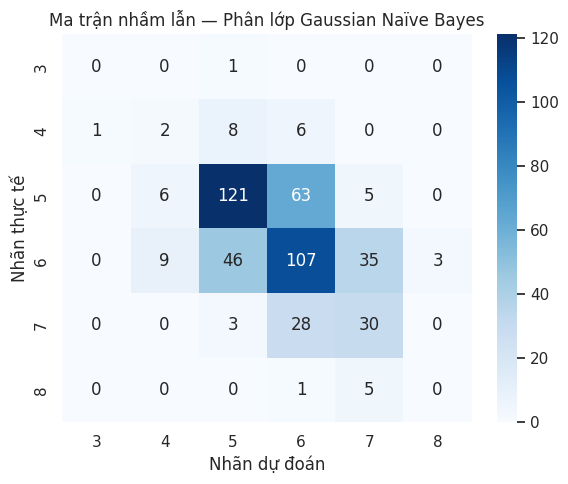

,sample_id,thuc_te,du_doan
0,803,6,5
1,124,5,5
2,350,6,6
3,682,5,5
4,1326,6,6
5,976,5,5
6,1493,5,5
7,706,5,5
8,613,5,6
9,1587,6,6


In [6]:
print("Đặng Ngọc Hiếu - 6451071024")

from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(X_train, y_train)
predicted = model.predict(X_test)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
classes = np.unique(np.concatenate([y_train.to_numpy(), y_test.to_numpy()]))
print("Accuracy:", accuracy_score(y_test, predicted))
print(classification_report(y_test, predicted, labels=classes,
    digits=4, zero_division=0))
# Nêu rõ trường hợp chỉ số precision bằng 0 vì lớp không được dự đoán.
missing_predictions = np.setdiff1d(classes, np.unique(predicted))
if len(missing_predictions):
    print("Các lớp không có dự đoán; precision quy ước bằng 0:", missing_predictions)
cm = confusion_matrix(y_test, predicted, labels=classes)
plt.figure(figsize=(max(6,len(classes)), max(5,len(classes)*0.8)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Ma trận nhầm lẫn — Phân lớp Gaussian Naïve Bayes")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()
plt.close()
output = ROOT / "Bai_4_Wine_Quality/outputs"
output.mkdir(exist_ok=True)
predictions = pd.DataFrame({"sample_id":y_test.index, "thuc_te":y_test.to_numpy(), "du_doan":predicted})
display(predictions.head(10))
# Lưu đầy đủ dự đoán để câu 10 so sánh, tránh huấn luyện lại mô hình.
predictions.to_csv(output / "Cau09_du_doan.csv", index=False)
